# 08b — Final Evaluation, Part 2: Neural Networks and Analysis

**Project:** Learning the Path of the Storm — 24-hour tropical cyclone track forecasting
**Author:** Yatharth Vardan · AAI-590 Capstone, University of San Diego

**Rubric section:** Model / Pipeline Analysis & Discussion (Study A final evaluation)

In part 1 (notebook 08a), the four baselines met the 2020–2024 test seasons for the first time. Here, we do
the same for every neural network the project trained, and then take the results apart:

- Which model wins, and are the gaps real?
- Did the validation seasons give an honest preview of the test seasons?
- How close do we get to the National Hurricane Center?
- Where, and for which storms, do the models still go wrong?

As in part 1, nothing is retrained. Each network is loaded exactly as its notebook saved it, together with the
scaling statistics it was trained with.

| | |
|---|---|
| **Inputs** | `tracks_clean.csv.gz`; `preds_test_baselines.csv` (08a); validation predictions from notebooks 04–06; saved networks and configs in `models/` |
| **Outputs** | `data/processed/preds_test_all.csv`, `final_results_test.csv`, figures `fig30`–`fig35` |

### Setting things up

Here, the imports match notebooks 04–06: PyTorch and the project's `rnn.py`, with XGBoost kept out of the
session. The NHC's official 24-hour Atlantic track error for 2020–2024, about **63 km**, serves as the
benchmark (National Hurricane Center, 2025).

In [1]:
# Imports and paths
import sys
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))

from stormtrack.data_io import load_clean, PROCESSED
from stormtrack.windows import (build_samples, build_sequences, persistence_displacement, track_error_km,
                                to_latlon, TARGET_COLS, STATIC_COLS)
from stormtrack.rnn import RNNForecaster, predict

FIG_DIR, MODEL_DIR = ROOT / "reports" / "figures", ROOT / "models"
torch.set_num_threads(4)
DEVICE = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
NHC_24H_ATL_KM = 63          # NHC official 24-h Atlantic track error, 2020-2024 mean (National Hurricane Center, 2025)
KW = dict(keep_default_na=False, na_values=[""], parse_dates=["ISO_TIME"])     # keep basin code "NA" as text
print(f"PyTorch {torch.__version__} | running on: {DEVICE}")

pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})

def savefig(fig, name):
    fig.savefig(FIG_DIR / name, dpi=150, bbox_inches="tight")
    print(f"saved reports/figures/{name}")

PyTorch 2.15.0 | running on: mps


## 1. Loading every network

Five neural forecasters were trained along the way, each saved as three networks (seeds 42, 7 and 2024) that
are averaged into an ensemble:

| Model | Notebook | Settings |
|---|---|---|
| LSTM, GRU | 04 | 24 h of history, 64 units |
| LSTM tuned, GRU tuned | 05 (round 1) | 48 h of history, 128 units |
| GRU round 2 | 06 (Optuna) | 48 h of history, 256 units × 2 layers, dropout 0.3: **the model chosen for the test seasons** |

Within the helper below, one ensemble is rebuilt from its config file. It lays out the history at the right length,
scales it with the statistics saved at training time (padding stays at zero), and loads the three sets of
weights. Then it turns predictions back into kilometres and adds persistence, since every network predicts a
correction to persistence.

In [2]:
tracks = load_clean()
S = build_samples(tracks)
BASINS = sorted(S["BASIN"].unique())
for b in BASINS:
    S[f"basin_{b}"] = (S["BASIN"] == b).astype(float)
STATIC = STATIC_COLS + [f"basin_{b}" for b in BASINS]
is_va, is_te = S["split"].eq("val").to_numpy(), S["split"].eq("test").to_numpy()
va, te = S[is_va].reset_index(drop=True), S[is_te].reset_index(drop=True)
SEQS = {}

def load_ensemble(config_file, cell, prefix):
    cfg = json.loads((MODEL_DIR / config_file).read_text())
    assert cfg["static_features"] == STATIC
    n = cfg["n_steps"]
    if n not in SEQS:
        SEQS[n] = build_sequences(tracks, S, n_steps=n)
    seq = SEQS[n]
    mu, sd = np.array(cfg["seq_mu"]), np.array(cfg["seq_sd"])
    seq_sc = np.where(seq[..., -1:] == 1, (seq - mu) / sd, 0.0).astype(np.float32)
    st = ((S[STATIC].to_numpy() - np.array(cfg["st_mu"])) / np.array(cfg["st_sd"])).astype(np.float32)
    nets = []
    for seed in cfg["seeds"]:
        net = RNNForecaster(seq.shape[2], len(STATIC), cell=cell, hidden=cfg["hidden"],
                            layers=cfg.get("layers", 1), dropout=cfg.get("dropout", 0.1))
        net.load_state_dict(torch.load(MODEL_DIR / f"{prefix}_seed{seed}.pt", map_location="cpu"))
        nets.append(net.to(DEVICE))

    def forecast(mask):
        with torch.no_grad():
            preds = [predict(net, torch.tensor(seq_sc[mask]), torch.tensor(st[mask]), DEVICE) for net in nets]
        return np.mean(preds, axis=0) * np.array(cfg["y_scale"]) + persistence_displacement(S[mask])
    return forecast

ENSEMBLES = {"LSTM": ("rnn_config.json", "lstm", "lstm"),
             "GRU": ("rnn_config.json", "gru", "gru"),
             "LSTM tuned": ("tuned_config.json", "lstm", "tuned_lstm"),
             "GRU tuned": ("tuned_config.json", "gru", "tuned_gru"),
             "GRU round 2": ("round2_config.json", "gru", "round2_gru")}
forecasters = {name: load_ensemble(*spec) for name, spec in ENSEMBLES.items()}
print("Loaded", len(forecasters), "ensembles of 3 networks each")

Loaded 5 ensembles of 3 networks each


Just like in part 1, the first job is proving these are the same models. The cell below scores each ensemble
on the validation seasons and compares the result, forecast by forecast, with the errors its own notebook
saved. Any mismatch in scaling, history length or weights would show up here.

In [3]:
saved_val = {"LSTM": ("preds_val_rnn.csv", "err_lstm_ens_km"), "GRU": ("preds_val_rnn.csv", "err_gru_ens_km"),
             "LSTM tuned": ("preds_val_tuned.csv", "err_lstm_tuned_km"), "GRU tuned": ("preds_val_tuned.csv", "err_gru_tuned_km"),
             "GRU round 2": ("preds_val_round2.csv", "err_round2_km")}
val_err, rows = {}, []
for name, f in forecasters.items():
    file, col = saved_val[name]
    saved = pd.read_csv(PROCESSED / file, **KW)
    assert (saved["SEG_ID"].to_numpy() == va["SEG_ID"].to_numpy()).all()
    val_err[name] = track_error_km(va, f(is_va))
    rows.append({"model": name, "saved_mean_km": saved[col].mean(), "reloaded_mean_km": val_err[name].mean(),
                 "largest_forecast_difference_km": np.abs(saved[col].to_numpy() - val_err[name]).max()})
check = pd.DataFrame(rows).set_index("model")
assert check["largest_forecast_difference_km"].max() < 1.0, "a reloaded ensemble doesn't match its notebook"
check.round(3)

,saved_mean_km,reloaded_mean_km,largest_forecast_difference_km
model,,,
LSTM,146.043,146.043,0.0
GRU,145.205,145.205,0.0
LSTM tuned,144.286,144.286,0.0
GRU tuned,143.952,143.952,0.0
GRU round 2,143.776,143.776,0.0


Every ensemble matches its notebook exactly, forecast by forecast (largest difference 0.000 km). So the configs, scaling statistics and weights all came back intact, and the test numbers below come from precisely the models that were evaluated on validation.

## 2. The test seasons: every model

Now the networks meet the test seasons. The cell below adds their errors to the baselines' errors from
08a, after checking that both notebooks lined the 6,745 test forecasts up in the same order, and builds the
final table. As in part 1, each model's validation mean sits next to its test results.

In [4]:
base = pd.read_csv(PROCESSED / "preds_test_baselines.csv", **KW)
assert (base["SEG_ID"].to_numpy() == te["SEG_ID"].to_numpy()).all() and (base["ISO_TIME"].to_numpy() == te["ISO_TIME"].to_numpy()).all()
base_val = pd.read_csv(PROCESSED / "preds_val_baselines.csv", **KW)

fc_te = {name: f(is_te) for name, f in forecasters.items()}
err = {m: base[f"err_{m.lower().replace(' ', '_')}_km"].to_numpy() for m in ("No motion", "Persistence", "Linear regression", "XGBoost")}
err.update({name: track_error_km(te, d) for name, d in fc_te.items()})
for m in ("No motion", "Persistence", "Linear regression", "XGBoost"):
    val_err[m] = base_val[f"err_{m.lower().replace(' ', '_')}_km"].to_numpy()

na, hi = te["BASIN"].eq("NA").to_numpy(), te["LAT"].abs().ge(25).to_numpy()
final = pd.DataFrame({m: {"val_mean_km": val_err[m].mean(), "test_mean_km": e.mean(), "test_median_km": np.median(e),
                          "test_p90_km": np.percentile(e, 90), "test_NA_km": e[na].mean(), "test_beyond_25deg_km": e[hi].mean()}
                      for m, e in err.items()}).T
final["skill_vs_persistence_%"] = 100 * (1 - final["test_mean_km"] / final.loc["Persistence", "test_mean_km"])
final["val_to_test_km"] = final["test_mean_km"] - final["val_mean_km"]
final.round(1)

,val_mean_km,test_mean_km,test_median_km,test_p90_km,test_NA_km,test_beyond_25deg_km,skill_vs_persistence_%,val_to_test_km
No motion,391.1,398.6,372.1,661.2,461.7,464.1,-137.5,7.4
Persistence,168.0,167.8,140.3,319.1,179.1,231.0,0.0,-0.2
Linear regression,158.3,159.8,135.1,301.0,159.7,205.9,4.7,1.5
XGBoost,148.5,150.3,128.3,278.6,155.1,197.2,10.4,1.8
LSTM,146.0,148.5,126.4,276.8,151.5,192.4,11.5,2.4
GRU,145.2,147.8,126.3,275.2,150.6,191.1,11.9,2.6
LSTM tuned,144.3,147.5,126.6,273.5,150.5,190.2,12.1,3.2
GRU tuned,144.0,146.9,125.5,273.9,149.2,189.4,12.5,2.9
GRU round 2,143.8,147.7,126.9,276.2,149.5,189.9,12.0,3.9


So, the full picture on the test seasons:

- **Every neural network beats every baseline.** The five ensembles land between 146.9 and 148.5 km, against 150.3 km for XGBoost and 167.8 km for persistence, roughly 12% skill over persistence.
- **The networks are bunched very tightly.** All five sit within 1.6 km of each other, with the round 1 tuned GRU lowest at 146.9 km and the chosen round 2 GRU at 147.7 km.
- **Every learned model lost a little between validation and test** (+1.5 to +3.9 km), while persistence didn't move. Here the pattern is telling: the more a model was selected on the validation seasons, the more it lost. The round 2 GRU, the product of the most selection, drifted the most (+3.9 km).

Next, the bootstrap over storms tells us which of these differences can be trusted. With 444 test storms, it
has more to work with than it did on the validation seasons. A positive number means the chosen model, the
round 2 GRU, is better.

In [5]:
def paired_bootstrap(err_a, err_b, groups, n_boot=2000, seed=42):
    diff = pd.DataFrame({"g": groups, "d": err_a - err_b}).groupby("g")["d"].agg(["sum", "size"])
    s, n = diff["sum"].to_numpy(), diff["size"].to_numpy()
    idx = np.random.default_rng(seed).integers(0, len(s), size=(n_boot, len(s)))
    boots = s[idx].sum(axis=1) / n[idx].sum(axis=1)
    return s.sum() / n.sum(), *np.percentile(boots, [2.5, 97.5])

others = ["Persistence", "Linear regression", "XGBoost", "LSTM", "GRU", "LSTM tuned", "GRU tuned"]
boot = pd.DataFrame([{"comparison": f"{m} minus GRU round 2",
                      **dict(zip(["mean_diff_km", "ci_low_km", "ci_high_km"], paired_bootstrap(err[m], err["GRU round 2"], te["SID"])))}
                     for m in others]).set_index("comparison").round(1)
boot

,mean_diff_km,ci_low_km,ci_high_km
comparison,,,
Persistence minus GRU round 2,20.1,17.4,22.8
Linear regression minus GRU round 2,12.1,10.1,14.2
XGBoost minus GRU round 2,2.6,1.3,3.8
LSTM minus GRU round 2,0.7,-0.1,1.6
GRU minus GRU round 2,0.0,-0.7,0.8
LSTM tuned minus GRU round 2,-0.2,-0.9,0.5
GRU tuned minus GRU round 2,-0.8,-1.4,-0.3


Against the simpler models, the chosen GRU's advantage is solid: it beats persistence by **20.1 km** (95% interval 17.4–22.8), linear regression by 12.1 km, and **XGBoost by 2.6 km (1.3–3.8)**. So the recurrent network's edge over gradient-boosted trees, first seen in notebook 04, holds up on storms it never saw.

Against the other networks, though, the picture is different. Round 2 ties the untuned GRU, the untuned LSTM and the tuned LSTM, and the round 1 tuned GRU actually beats it, by **0.8 km (0.3–1.4)**. That's small, but the interval excludes zero.

So it's worth being direct about what this means. Round 2 was chosen by a rule fixed before the test seasons were opened, and swapping it for round 1 now would be choosing a model by its test score, which would make the test set just another validation set. So round 2 stays the reported model. The honest lesson is that the 1–2 km gains from tuning on validation were mostly selection noise: once a recurrent network was in place, further tuning didn't buy anything that carried over to new seasons. In contrast, the big gaps (networks against XGBoost, and learned models against persistence) carried over cleanly.

Figure 30 puts the headline numbers side by side, for all basins and for the North Atlantic, with NHC's
official Atlantic error as the reference line.

saved reports/figures/fig30_final_test_results.png


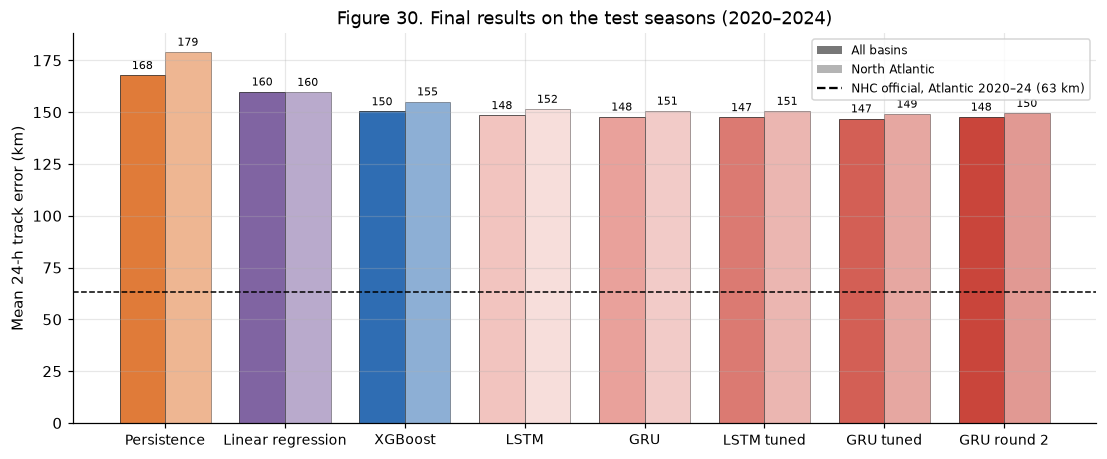

In [6]:
order = ["Persistence", "Linear regression", "XGBoost", "LSTM", "GRU", "LSTM tuned", "GRU tuned", "GRU round 2"]
colors = ["#E07B39", "#8064A2", "#2F6DB3", "#F2C4BF", "#E9A19B", "#DB7A72", "#D35F55", "#C9453B"]
fig, ax = plt.subplots(figsize=(12, 4.6))
x, w = np.arange(len(order)), 0.38
for k, (mask, lab) in enumerate([(slice(None), "All basins"), (na, "North Atlantic")]):
    vals = [err[m][mask].mean() for m in order]
    ax.bar(x + (k - 0.5) * w, vals, w, color=colors, alpha=1.0 if k == 0 else 0.55, edgecolor="k", lw=0.4)
    for xi, v in zip(x + (k - 0.5) * w, vals):
        ax.text(xi, v + 3, f"{v:.0f}", ha="center", fontsize=7.5)
ax.axhline(NHC_24H_ATL_KM, color="k", ls="--", lw=1)
ax.set_xticks(x, order, fontsize=9)
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
ax.legend(handles=[Patch(facecolor="#777", label="All basins"), Patch(facecolor="#777", alpha=0.55, label="North Atlantic"),
                   Line2D([], [], color="k", ls="--", label="NHC official, Atlantic 2020–24 (63 km)")], fontsize=8)
ax.set(ylabel="Mean 24-h track error (km)", title="Figure 30. Final results on the test seasons (2020–2024)")
savefig(fig, "fig30_final_test_results.png")
plt.show()

## 3. Did validation tell the truth?

After all, a held-out test set is only worth having if it can disagree with validation. So it's worth asking directly:
did the models keep the same order, and by roughly the same margins? Figure 31 draws each model's validation
error next to its test error.

saved reports/figures/fig31_validation_vs_test.png


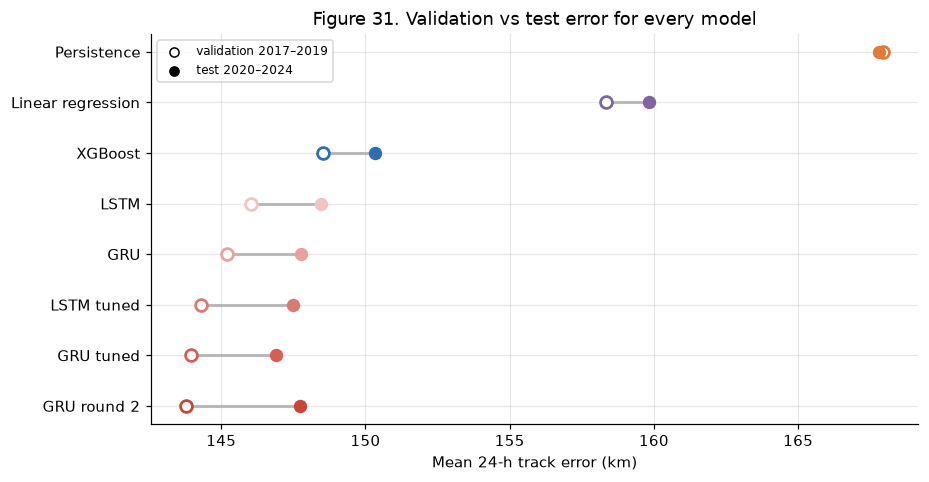

Spearman rank correlation, validation vs test: 0.929


,Persistence,Linear regression,XGBoost,LSTM,GRU,LSTM tuned,GRU tuned,GRU round 2
val_rank,8,7,6,5,4,3,2,1
test_rank,8,7,6,5,4,2,1,3


In [7]:
fig, ax = plt.subplots(figsize=(9, 4.6))
y = np.arange(len(order))[::-1]
for yi, m, c in zip(y, order, colors):
    v, t = final.loc[m, "val_mean_km"], final.loc[m, "test_mean_km"]
    ax.plot([v, t], [yi, yi], color="#BBB", lw=2, zorder=1)
    ax.scatter(v, yi, color="white", edgecolor=c, s=60, lw=1.8, zorder=2)
    ax.scatter(t, yi, color=c, s=60, zorder=3)
ax.scatter([], [], color="white", edgecolor="k", label="validation 2017–2019")
ax.scatter([], [], color="k", label="test 2020–2024")
ax.set_yticks(y, order)
ax.set(xlabel="Mean 24-h track error (km)", title="Figure 31. Validation vs test error for every model")
ax.legend(fontsize=8)
savefig(fig, "fig31_validation_vs_test.png")
plt.show()
rank = pd.DataFrame({"val_rank": final.loc[order, "val_mean_km"].rank().astype(int),
                     "test_rank": final.loc[order, "test_mean_km"].rank().astype(int)})
print("Spearman rank correlation, validation vs test:", round(rank.corr(method="spearman").iloc[0, 1], 3))
rank.T

Overall, validation ranked the models well: the rank correlation between validation and test is **0.93**. The order of the model *families* is exactly preserved: persistence, then linear regression, then XGBoost, then the networks. Only within the tightly bunched networks does the order shuffle, which is what you'd expect when the gaps between them are smaller than the noise. Figure 31 shows the whole picture: every learned model shifted right by a similar couple of kilometres, while persistence stayed put.

## 4. How close to the National Hurricane Center?

So, the comparison everyone asks about first. The NHC's official 24-hour track forecasts for the Atlantic
erred by about 63 km on average over 2020–2024. The cell below lines that up against our North Atlantic
errors, season by season.

Before reading the numbers, it's worth being clear about what the comparison is and isn't. NHC forecasters
work with the full picture: satellite and aircraft observations, and guidance from global weather models that
simulate the whole atmosphere. Our models see only the storm's own track. In one respect we are even
favoured, since our forecasts start from the final best-track position, which is more accurate than the
position a forecaster knows in real time. So the gap measures how much information a track-only model is
missing, not a contest on equal terms.

In [8]:
na_by_season = pd.DataFrame({m: pd.Series(err[m][na]).groupby(te.loc[na, "SEASON"].to_numpy()).mean()
                             for m in ["Persistence", "XGBoost", "GRU round 2"]})
na_by_season["NA forecasts"] = te.loc[na, "SEASON"].value_counts().sort_index()
na_by_season.loc["2020-2024"] = [err[m][na].mean() for m in ["Persistence", "XGBoost", "GRU round 2"]] + [na.sum()]
na_by_season["GRU round 2 / NHC"] = na_by_season["GRU round 2"] / NHC_24H_ATL_KM
na_by_season.round(2)

,Persistence,XGBoost,GRU round 2,NA forecasts,GRU round 2 / NHC
2020,191.56,167.82,157.53,406.0,2.50
2021,179.36,154.34,150.21,262.0,2.38
2022,180.87,157.25,154.78,163.0,2.46
2023,172.80,144.57,145.30,333.0,2.31
2024,164.89,147.44,137.38,237.0,2.18
2020-2024,179.06,155.09,149.53,1401.0,2.37


So, in the North Atlantic, the chosen GRU averages **149.5 km**, about **2.4 times** NHC's 63 km. Season by season the ratio ranges from 2.2 (2024, at 137 km) to 2.5 (2020). The GRU beats XGBoost in four of the five seasons; in 2023 the two are level (145.3 against 144.6 km).

That gap is no surprise, and Study B (notebooks 07a–07b) already pointed at its main cause. Adding a single snapshot of the steering winds cut errors by about 13 km there. NHC's forecasts go much further: global weather models carry the whole atmosphere forward in time, so they can see the steering flow *change* over the next 24 hours, and forecasters add satellite and aircraft observations on top. A model that sees only the storm's own track can learn its habits, but not the weather it's about to run into.

## 5. Where do the errors come from?

Averages hide a lot, so in this section we break the test errors down in four ways (Figures 32 and 33):

- **by basin**, since each ocean has its own steering patterns;
- **by latitude**, where the EDA found persistence breaking down past 25–30°;
- **by intensity**, comparing tropical depressions, tropical storms and hurricanes/typhoons;
- **by season**, to see whether any single year drives the result.

Throughout, the three models shown are persistence, XGBoost and the chosen round 2 GRU.

saved reports/figures/fig32_test_error_by_basin_latitude.png


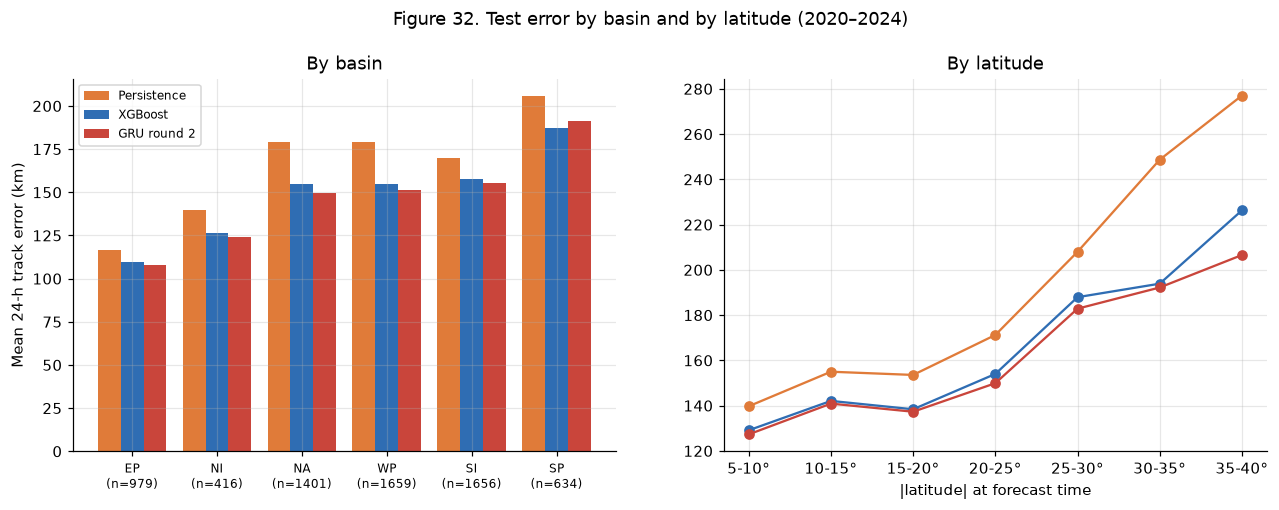

       Persistence  XGBoost  GRU round 2  forecasts
basin                                              
EP           116.3    109.9        107.8        979
NI           139.7    126.7        123.9        416
NA           179.1    155.1        149.5       1401
WP           179.4    154.6        151.4       1659
SI           169.6    157.7        155.5       1656
SP           205.6    187.3        191.1        634

          Persistence  XGBoost  GRU round 2  forecasts
lat_band                                              
5               139.7    129.1        127.3        327
10              155.0    142.1        140.9       1642
15              153.6    138.4        137.3       2528
20              171.2    154.0        149.9       1251
25              208.0    187.9        182.8        563
30              248.7    193.9        192.2        259
35              277.0    226.3        206.6        140


In [9]:
show = ["Persistence", "XGBoost", "GRU round 2"]
cols3 = {"Persistence": "#E07B39", "XGBoost": "#2F6DB3", "GRU round 2": "#C9453B"}
E = pd.DataFrame({m: err[m] for m in show})
E["basin"], E["season"] = te["BASIN"].to_numpy(), te["SEASON"].to_numpy()
E["lat_band"] = (te["LAT"].abs() // 5 * 5).astype(int).to_numpy()
E["intensity"] = pd.cut(te["wind_kt"], [-1, 33, 63, 1000],
                        labels=["Depression (<34 kt)", "Tropical storm (34–63 kt)", "Hurricane/typhoon (64+ kt)"]).to_numpy()

def grouped(key, min_n=50):
    g = E.groupby(key, observed=True)[show].mean()
    g["forecasts"] = E.groupby(key, observed=True).size()
    return g[g["forecasts"] >= min_n]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
by_basin = grouped("basin").sort_values("GRU round 2")
xb = np.arange(len(by_basin)); wb = 0.27
for k, m in enumerate(show):
    axes[0].bar(xb + (k - 1) * wb, by_basin[m], wb, color=cols3[m], label=m)
axes[0].set_xticks(xb, [f"{b}\n(n={n})" for b, n in zip(by_basin.index, by_basin["forecasts"])], fontsize=8)
axes[0].set(ylabel="Mean 24-h track error (km)", title="By basin")
axes[0].legend(fontsize=8)
by_lat = grouped("lat_band")
for m in show:
    axes[1].plot([f"{b}-{b+5}°" for b in by_lat.index], by_lat[m], "o-", color=cols3[m], label=m)
axes[1].set(xlabel="|latitude| at forecast time", title="By latitude")
fig.suptitle("Figure 32. Test error by basin and by latitude (2020–2024)", y=1.02)
savefig(fig, "fig32_test_error_by_basin_latitude.png")
plt.show()
print(by_basin.round(1).to_string())
print()
print(by_lat.round(1).to_string())

Here, a few patterns stand out:

- **By basin**, the eastern North Pacific is easiest (108 km), where storms mostly ride steady easterlies westward. The South Pacific is hardest (191 km), and it's the one basin where XGBoost edges out the GRU (187.3 km against 191.1 km).
- **By latitude**, errors climb from about 127 km near the equator to over 200 km beyond 35°, exactly the recurvature effect seen in the EDA. Crucially, the learned models' advantage over persistence grows with latitude: about 12 km at 5–10°, 25 km at 25–30°, and 70 km beyond 35°. The GRU's clearest edge over XGBoost is also furthest poleward (207 against 226 km beyond 35°), although only 140 forecasts sit in that band.

saved reports/figures/fig33_test_error_by_intensity_season.png


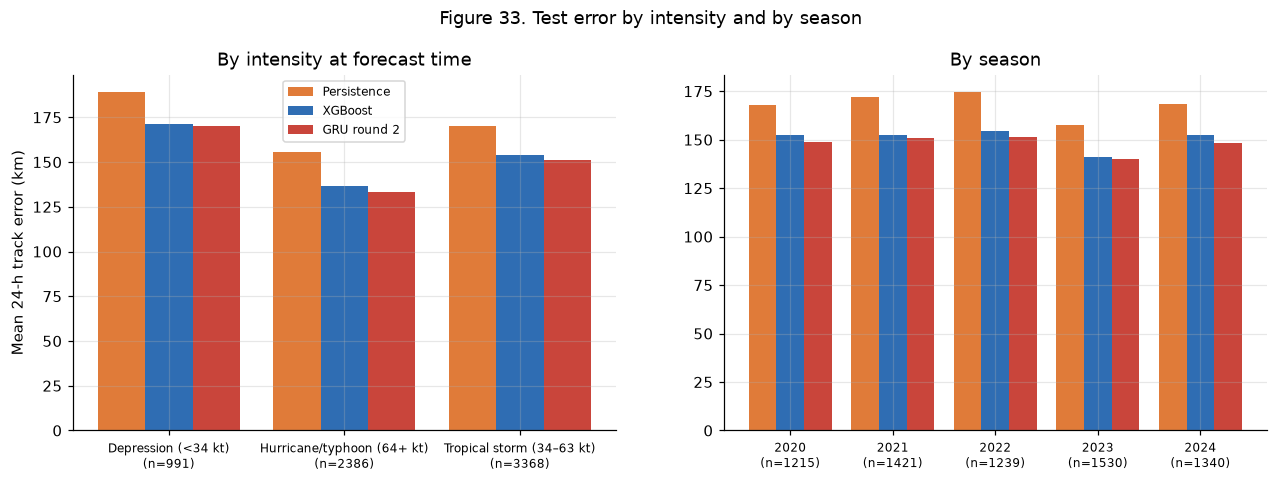

                            Persistence  XGBoost  GRU round 2  forecasts
intensity                                                               
Depression (<34 kt)               189.3    171.4        170.0        991
Hurricane/typhoon (64+ kt)        155.7    136.8        133.4       2386
Tropical storm (34–63 kt)         170.0    153.7        151.3       3368

        Persistence  XGBoost  GRU round 2  forecasts
season                                              
2020          168.1    152.7        149.1       1215
2021          172.2    152.6        151.0       1421
2022          174.8    154.5        151.6       1239
2023          157.4    140.9        140.0       1530
2024          168.2    152.7        148.2       1340


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
by_int, by_season = grouped("intensity"), grouped("season")
for ax, tab, title in ((axes[0], by_int, "By intensity at forecast time"), (axes[1], by_season, "By season")):
    xi = np.arange(len(tab))
    for k, m in enumerate(show):
        ax.bar(xi + (k - 1) * 0.27, tab[m], 0.27, color=cols3[m], label=m)
    ax.set_xticks(xi, [f"{i}\n(n={n})" for i, n in zip(tab.index, tab["forecasts"])], fontsize=8)
    ax.set_title(title)
axes[0].set_ylabel("Mean 24-h track error (km)")
axes[0].legend(fontsize=8)
fig.suptitle("Figure 33. Test error by intensity and by season", y=1.02)
savefig(fig, "fig33_test_error_by_intensity_season.png")
plt.show()
print(by_int.round(1).to_string())
print()
print(by_season.round(1).to_string())

Somewhat counter-intuitively, the **strongest storms are the easiest to forecast** (133 km for hurricanes and typhoons) and **depressions the hardest** (170 km). That's a known pattern: a weak system has a loosely organised centre that is harder to pin down, even in the best track, and it is pushed around by shallower, more changeable winds. A strong storm reaches deep into the atmosphere and is carried by the steadier deep-layer flow.

Across seasons the results are steady, between 140 and 152 km, with 2023 the easiest year. The GRU beats XGBoost in every season, so no single year drives the result.

## 6. The whole distribution of errors

Means can be pulled around by a handful of very bad forecasts. Figure 34 shows the full picture instead:
for every error distance, the share of test forecasts that landed within it. A curve further up and to the
left is better, and the gap between curves shows where the gain sits, whether in typical forecasts or in the
bad ones.

saved reports/figures/fig34_test_error_cdf.png


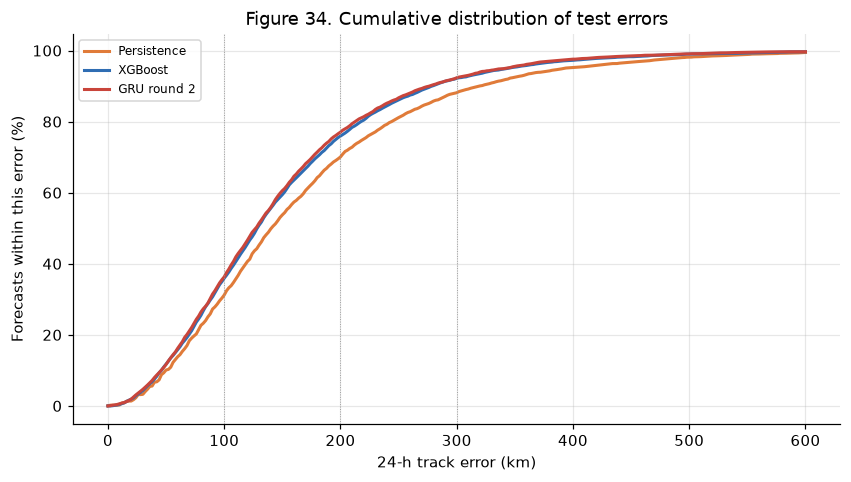

,Persistence,XGBoost,GRU round 2
within 50 km (%),10.1,11.8,11.7
within 100 km (%),31.2,35.9,36.3
within 200 km (%),70.1,76.0,77.0
within 300 km (%),88.1,92.2,92.3
worst 1% starts at (km),553.0,497.1,490.1


In [11]:
fig, ax = plt.subplots(figsize=(9, 4.6))
grid = np.linspace(0, 600, 301)
for m in show:
    ax.plot(grid, [(err[m] <= g).mean() * 100 for g in grid], color=cols3[m], lw=2, label=m)
for q in (100, 200, 300):
    ax.axvline(q, color="#999", lw=0.6, ls=":")
ax.set(xlabel="24-h track error (km)", ylabel="Forecasts within this error (%)",
       title="Figure 34. Cumulative distribution of test errors")
ax.legend(fontsize=8)
savefig(fig, "fig34_test_error_cdf.png")
plt.show()
pd.DataFrame({m: {f"within {q} km (%)": (err[m] <= q).mean() * 100 for q in (50, 100, 200, 300)} | {"worst 1% starts at (km)": np.percentile(err[m], 99)}
              for m in show}).round(1)

So, the improvement over persistence isn't confined to one part of the distribution. The GRU puts 36% of forecasts within 100 km (persistence: 31%) and 77% within 200 km (persistence: 70%), and its worst 1% begins at 490 km rather than 553 km. The GRU and XGBoost are almost indistinguishable for the best forecasts; their small difference comes from the middle of the range, roughly 100–200 km.

To see what the worst cases have in common, the cell below lists the 1% of test forecasts where the
round 2 GRU erred most, and compares them with the test set as a whole.

In [12]:
worst = te[err["GRU round 2"] >= np.percentile(err["GRU round 2"], 99)].copy()
worst["err_km"] = err["GRU round 2"][worst.index]
speed = lambda d: np.hypot(d["dx_m0"], d["dy_m0"]) / 6          # km/h over the last 6 hours
turn = lambda d: np.hypot(d["dx_target"] - 4 * d["dx_m0"], d["dy_target"] - 4 * d["dy_m0"])   # persistence error, km
profile = pd.DataFrame({"worst 1%": {"forecasts": len(worst), "mean |latitude|": worst["LAT"].abs().mean(),
                                     "mean speed now (km/h)": speed(worst).mean(), "mean wind (kt)": worst["wind_kt"].mean(),
                                     "persistence error (km)": turn(worst).mean(), "share North Atlantic (%)": 100 * worst["BASIN"].eq("NA").mean()},
                        "all test": {"forecasts": len(te), "mean |latitude|": te["LAT"].abs().mean(),
                                     "mean speed now (km/h)": speed(te).mean(), "mean wind (kt)": te["wind_kt"].mean(),
                                     "persistence error (km)": turn(te).mean(), "share North Atlantic (%)": 100 * te["BASIN"].eq("NA").mean()}})
display(profile.round(1))
worst.merge(tracks[["SID", "NAME"]].drop_duplicates(), on="SID")[["NAME", "SEASON", "BASIN", "ISO_TIME", "LAT", "wind_kt", "err_km"]] \
     .sort_values("err_km", ascending=False).head(10).round({"LAT": 1, "err_km": 1})

,worst 1%,all test
forecasts,68.0,6745.0
mean |latitude|,23.7,18.6
mean speed now (km/h),21.1,16.4
mean wind (kt),49.2,59.4
persistence error (km),566.7,169.3
share North Atlantic (%),32.4,20.8


,NAME,SEASON,BASIN,ISO_TIME,LAT,wind_kt,err_km
26,HENRI,2021,NA,2021-08-22 00:00:00,37.6,65.0,861.5
5,TEDDY,2020,NA,2020-09-21 18:00:00,32.2,80.0,820.1
53,IRENE,2023,SP,2023-01-17 00:00:00,-17.2,25.0,740.8
60,TAMMY,2023,NA,2023-10-25 18:00:00,27.5,85.0,730.7
48,MARTIN,2022,NA,2022-11-02 06:00:00,35.0,55.0,714.9
56,JUDY,2023,SP,2023-03-02 18:00:00,-24.8,80.0,710.9
54,DINGANI,2023,SI,2023-02-03 18:00:00,-12.8,25.0,695.1
46,HAITANG,2022,WP,2022-10-13 18:00:00,16.8,35.0,688.0
4,TEDDY,2020,NA,2020-09-21 12:00:00,30.5,80.0,670.2
37,VERNON,2022,SI,2022-02-26 12:00:00,-13.9,90.0,644.7


Looking at the worst 1%, a clear profile emerges. These storms sit further from the equator (23.7° against 18.6° on average), are moving faster (21 against 16 km/h), and are somewhat weaker. Above all, persistence would have missed them by **567 km** on average, more than three times its usual miss. In other words, these are storms that suddenly changed speed or direction: stalls, loops and sharp accelerations. The North Atlantic is over-represented (32% against 21%), with names like Henri (2021), Teddy (2020) and Tammy (2023) at the top. Those are exactly the situations where the change comes from the surrounding weather rather than from anything in the storm's recent track.

## 7. A storm up close

Finally, one storm from the test seasons. To keep the choice honest, we use the same rule as notebook 03:
the North Atlantic test segment with the biggest total change of direction. Figure 35 draws the 24-hour
forecasts from persistence, XGBoost and the round 2 GRU every 12 hours along its track.

saved reports/figures/fig35_test_example_storm.png


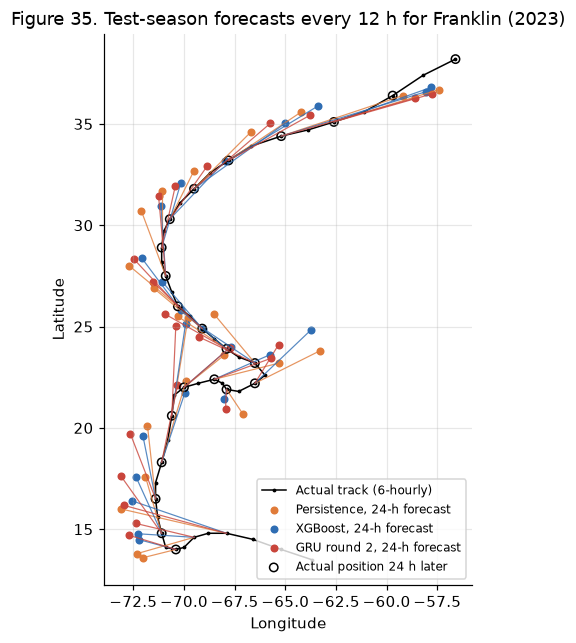

Franklin (2023): 43 forecasts; mean error persistence 194 km, XGBoost 164 km, GRU round 2 180 km


In [13]:
te["lat_gru"], te["lon_gru"] = to_latlon(te["LAT"], te["LON"], fc_te["GRU round 2"][:, 0], fc_te["GRU round 2"][:, 1])
test_na = tracks[tracks["SEG_ID"].isin(te.loc[na, "SEG_ID"])]
turning = test_na.groupby("SEG_ID")["heading_deg"].agg(lambda h: np.abs(((h.diff() + 180) % 360) - 180).sum())
seg = turning.idxmax()
trk = tracks[tracks["SEG_ID"] == seg]
sel = (te["SEG_ID"] == seg).to_numpy()
fc = te[sel].iloc[::2]
b = base[sel].iloc[::2]
name, season = trk["NAME"].iloc[0].title(), trk["SEASON"].iloc[0]

fig, ax = plt.subplots(figsize=(8.5, 6.5))
ax.plot(trk["LON"], trk["LAT"], "k.-", lw=1, ms=3, label="Actual track (6-hourly)")
for lat_c, lon_c, c, lab in ((b["pred_lat_persistence"], b["pred_lon_persistence"], cols3["Persistence"], "Persistence"),
                             (b["pred_lat_xgboost"], b["pred_lon_xgboost"], cols3["XGBoost"], "XGBoost"),
                             (fc["lat_gru"], fc["lon_gru"], cols3["GRU round 2"], "GRU round 2")):
    for x0, y0, x1, y1 in zip(fc["LON"], fc["LAT"], lon_c, lat_c):
        ax.plot([x0, x1], [y0, y1], color=c, lw=0.8, alpha=0.8)
    ax.scatter(lon_c, lat_c, color=c, s=18, label=f"{lab}, 24-h forecast")
ax.scatter(fc["lon_true"], fc["lat_true"], facecolor="none", edgecolor="k", s=30, label="Actual position 24 h later")
ax.set(xlabel="Longitude", ylabel="Latitude", aspect="equal", title=f"Figure 35. Test-season forecasts every 12 h for {name} ({season})")
ax.legend(fontsize=8, loc="best")
savefig(fig, "fig35_test_example_storm.png")
plt.show()
print(f"{name} ({season}): {sel.sum()} forecasts; mean error persistence {err['Persistence'][sel].mean():.0f} km, "
      f"XGBoost {err['XGBoost'][sel].mean():.0f} km, GRU round 2 {err['GRU round 2'][sel].mean():.0f} km")

By the rule, the example is **Franklin (2023)**, which crossed Hispaniola heading north, wandered and looped north of the island, then recurved out to sea. As it happens, it's a storm where XGBoost (164 km) clearly beats the GRU (180 km), with persistence at 194 km. On the loop near 22–24°N, every model overshoots; once Franklin settles onto its northeastward path, all three track it closely. So it's a good reminder that a 2.6 km average edge is small next to the storm-to-storm variation. The chosen model is better on average, not on every storm.

## 8. Saving the final results

Last, we save the final table and every model's error on every test forecast, so the report's tables and any
later analysis come straight from these files.

In [14]:
final.round(2).to_csv(PROCESSED / "final_results_test.csv")
out = base[["SID", "SEG_ID", "BASIN", "SEASON", "ISO_TIME", "LAT", "LON", "lat_true", "lon_true", "wind_kt"]].copy()
for m, e in err.items():
    out[f"err_{m.lower().replace(' ', '_')}_km"] = e
out.to_csv(PROCESSED / "preds_test_all.csv", index=False)
print("saved data/processed/final_results_test.csv, data/processed/preds_test_all.csv")

saved data/processed/final_results_test.csv, data/processed/preds_test_all.csv


## Summary

**Final results on the 2020–2024 test seasons (6,745 forecasts, 444 storms):**

| Model | Mean error | North Atlantic | Skill vs persistence |
|---|---|---|---|
| Persistence | 167.8 km | 179.1 km | 0% |
| XGBoost | 150.3 km | 155.1 km | 10.4% |
| **GRU round 2 (chosen)** | **147.7 km** | **149.5 km** | **12.0%** |
| GRU tuned, round 1 (best on test) | 146.9 km | 149.2 km | 12.5% |

- **The neural networks win.** Every recurrent ensemble beats every baseline, and the chosen GRU beats XGBoost by 2.6 km (95% CI 1.3–3.8) and persistence by 20.1 km.
- **Validation was a reliable guide** to model families (rank correlation 0.93), but not to the small differences between tuned networks. The round 1 GRU beat the chosen round 2 GRU by 0.8 km on test, so the tuning gains were mostly selection noise. Round 2 stays the reported model, because it was chosen before the test seasons were opened.
- **The learned models help most where forecasting is hardest:** at higher latitudes, where storms recurve, and in the worst cases.
- **We're still about 2.4 times NHC's 63 km error in the Atlantic.** The worst forecasts are sudden stalls, loops and accelerations driven by the surrounding weather, which a track-only model can't see.

**Where the two studies meet.** Study A shows that a well-built recurrent network gets about as far as the track history allows, around 147 km. Study B shows the way past that ceiling: adding steering winds from a second dataset cut errors by 13–15 km for every model, several times more than any tuning or architecture change. Within this project's scope, the most valuable next step is more information about the atmosphere, not a bigger model: winds for every year, at finer resolution, and ideally forecast winds for the next 24 hours rather than a single snapshot.

## References

Cho, K., van Merriënboer, B., Gulcehre, C., Bahdanau, D., Bougares, F., Schwenk, H., & Bengio, Y. (2014).
Learning phrase representations using RNN encoder–decoder for statistical machine translation. In
*Proceedings of the 2014 Conference on Empirical Methods in Natural Language Processing* (pp. 1724–1734).
https://doi.org/10.3115/v1/D14-1179

Gahtan, J., Knapp, K. R., Schreck, C. J., Diamond, H. J., Kossin, J. P., & Kruk, M. C. (2024).
*International Best Track Archive for Climate Stewardship (IBTrACS) Project, Version 4r01*. NOAA National
Centers for Environmental Information. https://doi.org/10.25921/82ty-9e16

Hochreiter, S., & Schmidhuber, J. (1997). Long short-term memory. *Neural Computation, 9*(8), 1735–1780.
https://doi.org/10.1162/neco.1997.9.8.1735

National Hurricane Center. (2025). *Official Atlantic basin annual average track errors, 1989–present*
[Data set]. National Oceanic and Atmospheric Administration.
https://www.nhc.noaa.gov/verification/pdfs/1989-present_OFCL_ATL_annual_trk_errors.pdf

*AI-tool disclosure: Claude (Anthropic) helped draft this notebook's code and explanations. The author
reviewed each step, ran the notebook, and checked the outputs.*